In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

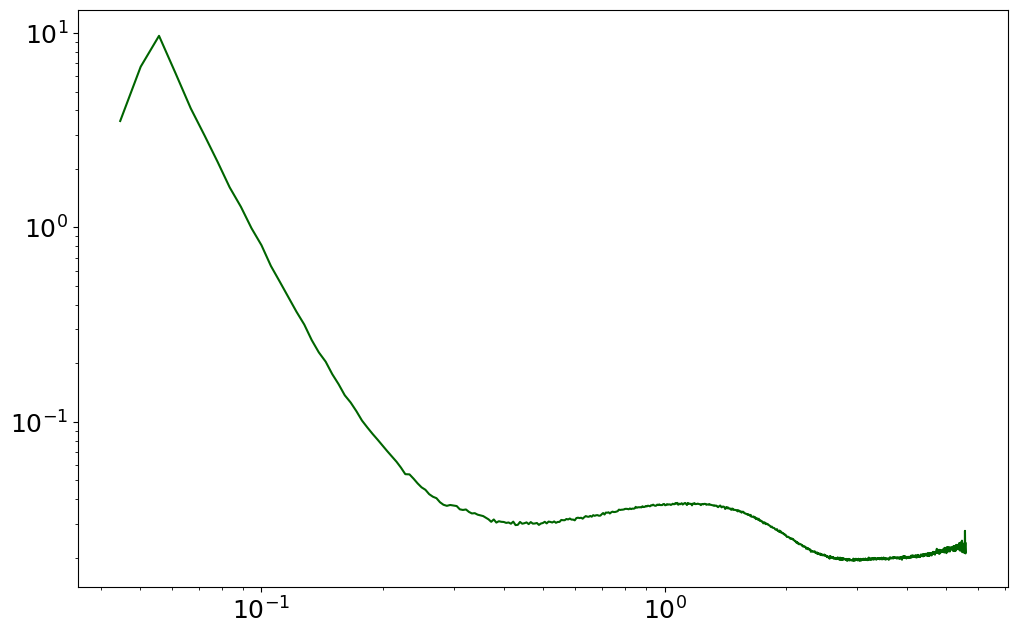

In [4]:
BVII_S4_raw_path = Path("C:/Users/rikoh/Documents/Physik Göttingen&Grenoble 2022-2026/8. SoSe 26/SHK Synaptische Proteine, Lipidmembranen SoSe 2026/Code/BM29_data_and_analysis/data_BM29_2026/BVII/sample_BVII_S40000-subtract/sample/data.dat")

q_sample, I_sample, I_err_Poisson = np.loadtxt(BVII_S4_raw_path, unpack=True, delimiter=",", skiprows=1, encoding="utf-8")
plt.figure(figsize=(12,7.5))
plt.loglog(q_sample, I_sample, label="BVII_S4 raw", color="darkgreen")



Sample BVII_S4_15mM_DOPC_DOPS_75uM_aSynWT is now averaged and background is subtracted ...


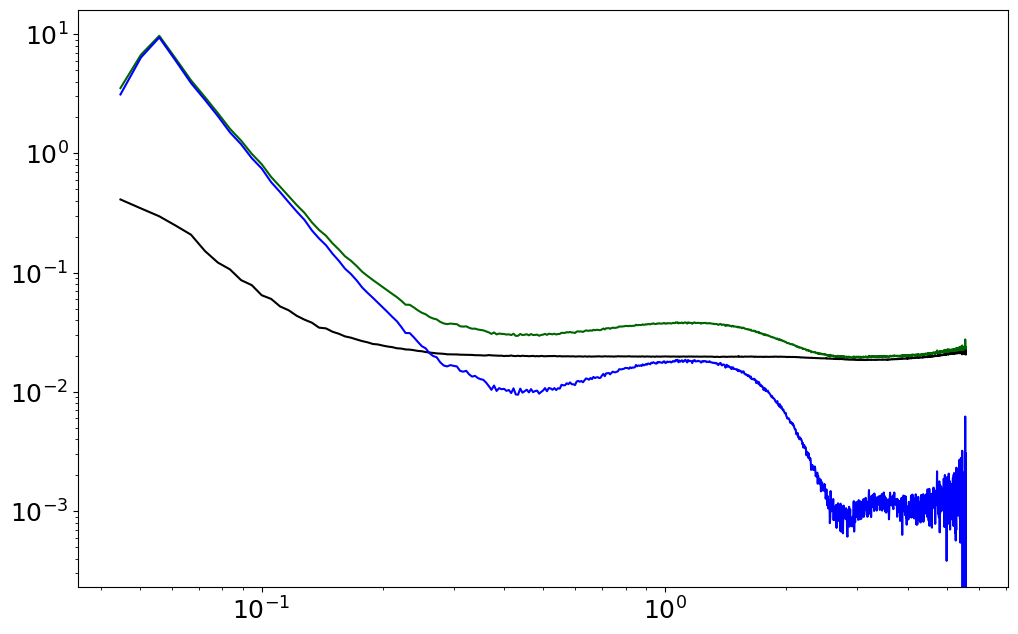

In [18]:
def average_dat_files(dat_files):
    """
    Each .dat file must have three columns: q, I, sigma_I.
    Returns q, I_avg, sigma_avg arrays.
    """
    data = []
    for f in dat_files:
        with open(f, "r", encoding="latin-1") as k:
            first_line = k.readline()

        if "," in first_line:
            dat = np.loadtxt(
                f,
                delimiter=",",
                skiprows=1,
                encoding="latin-1"
            )
        else:
            dat = np.loadtxt(
                f,
                comments="#",
                encoding="latin-1"
            )
        data.append(dat)
    q = data[0][:, 0]
    I = np.array([d[:, 1] for d in data])
    sigma = np.array([d[:, 2] for d in data])
    sigma[sigma <= 1e-10] = 1e-10

    # weighted average: weights = 1 / sigma^2
    w = 1 / sigma**2
    I_avg = np.sum(I * w, axis=0) / np.sum(w, axis=0)
    sigma_avg = np.sqrt(1 / np.sum(w, axis=0))

    return q, I_avg, sigma_avg
def save_dat(filename, q, I, sigma):

    arr = np.column_stack([q, I, sigma])
    np.savetxt(filename, arr, fmt="%.10e") # fmt sets precision, header is also an argument

def averaging_and_bgr_subtraction_BVII_S4(sample, fac=0.78):
    sample_short, block = BM29.extract_sample_name(sample)
    sample_path = BM29.blockpath(block) / sample
    print(f"Sample {BM29.sample_dict[sample_short]} is now averaged and background is subtracted ...")

    buffer_0_path = sample_path / "buffer_0"
    buffer_1_path = sample_path / "buffer_1"
    sample_dat_path = sample_path / "sample" 

    buffer_paths = [buffer_0_path, buffer_1_path]

    buffer_files = []
    for path in buffer_paths: 
        dat_files = list(path.glob("*.dat"))
        buffer_files.extend(dat_files)
    sample_files = list(sample_dat_path.glob("*.dat"))

    plt.figure(figsize=(12, 7.5))
    q, I_RAW, I_RAW_err = average_dat_files(sample_files)
    _, I_bgr, I_bgr_err = average_dat_files(buffer_files)
    plt.loglog(q, I_RAW, c="darkgreen")
    plt.loglog(q, I_bgr * fac, c="black")

    I_SUB = I_RAW - I_bgr * fac
    I_SUB_err = np.sqrt(I_RAW_err**2 + (I_bgr_err)**2)
    # plt.loglog(q, I_SUB)
    plt.loglog(q, I_SUB, c="blue")

    sub_folder = sample_path / "avg_and_sub"
    if not sub_folder.exists():
        sub_folder.mkdir()
    save_dat(sub_folder / (BM29.sample_dict[sample_short]), q, I_SUB, I_SUB_err)
    return

sample = "sample_BVII_S40000-subtract"
averaging_and_bgr_subtraction_BVII_S4(sample)

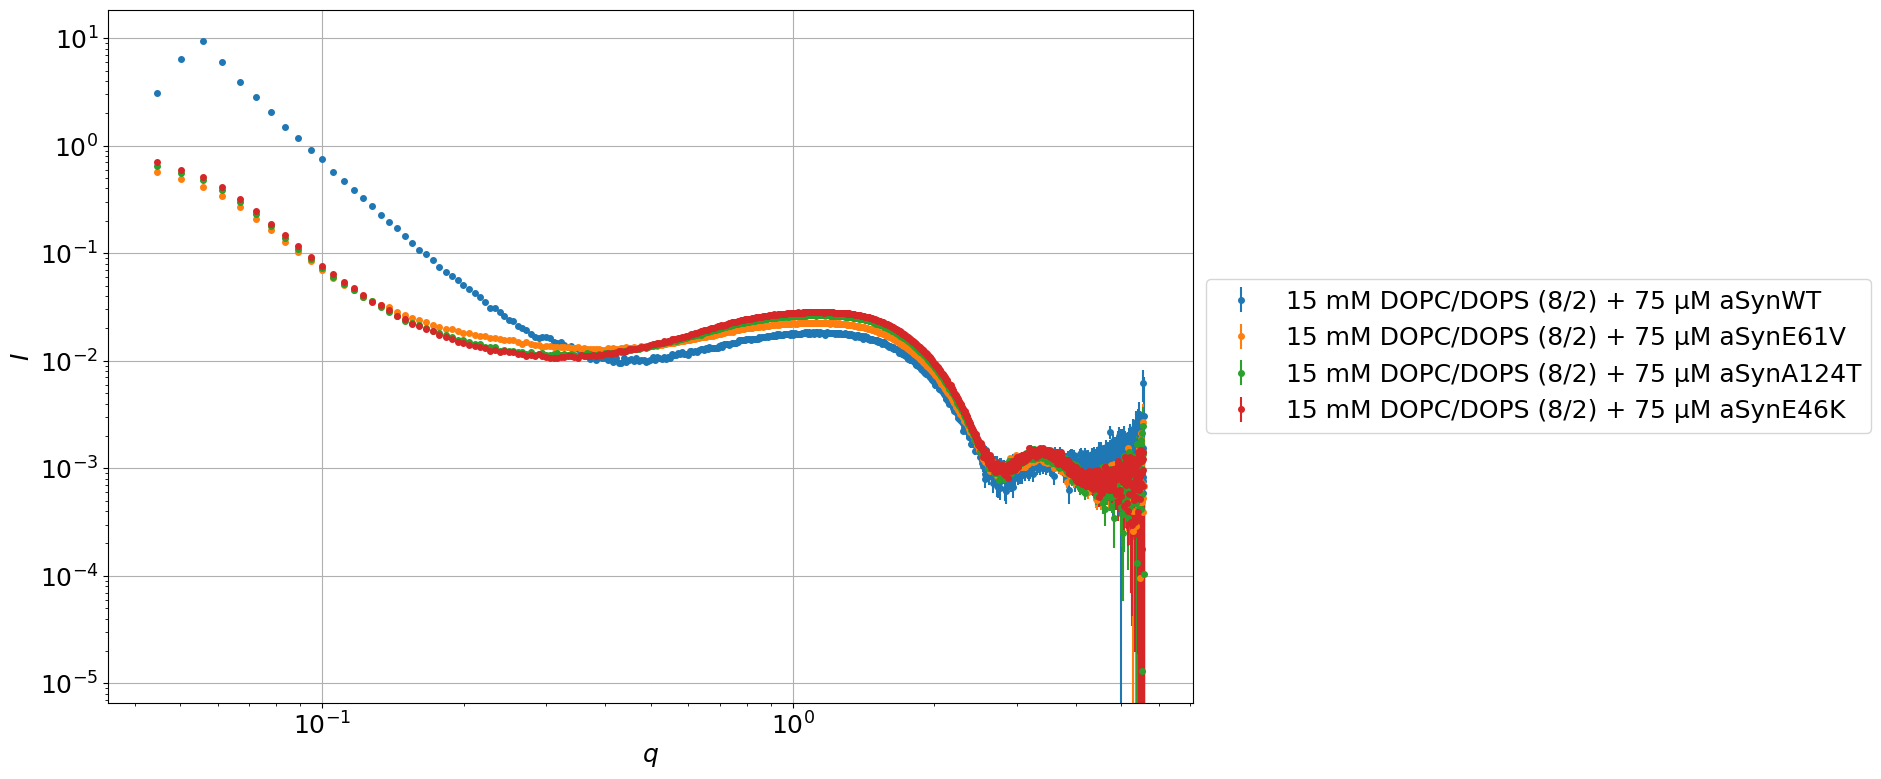

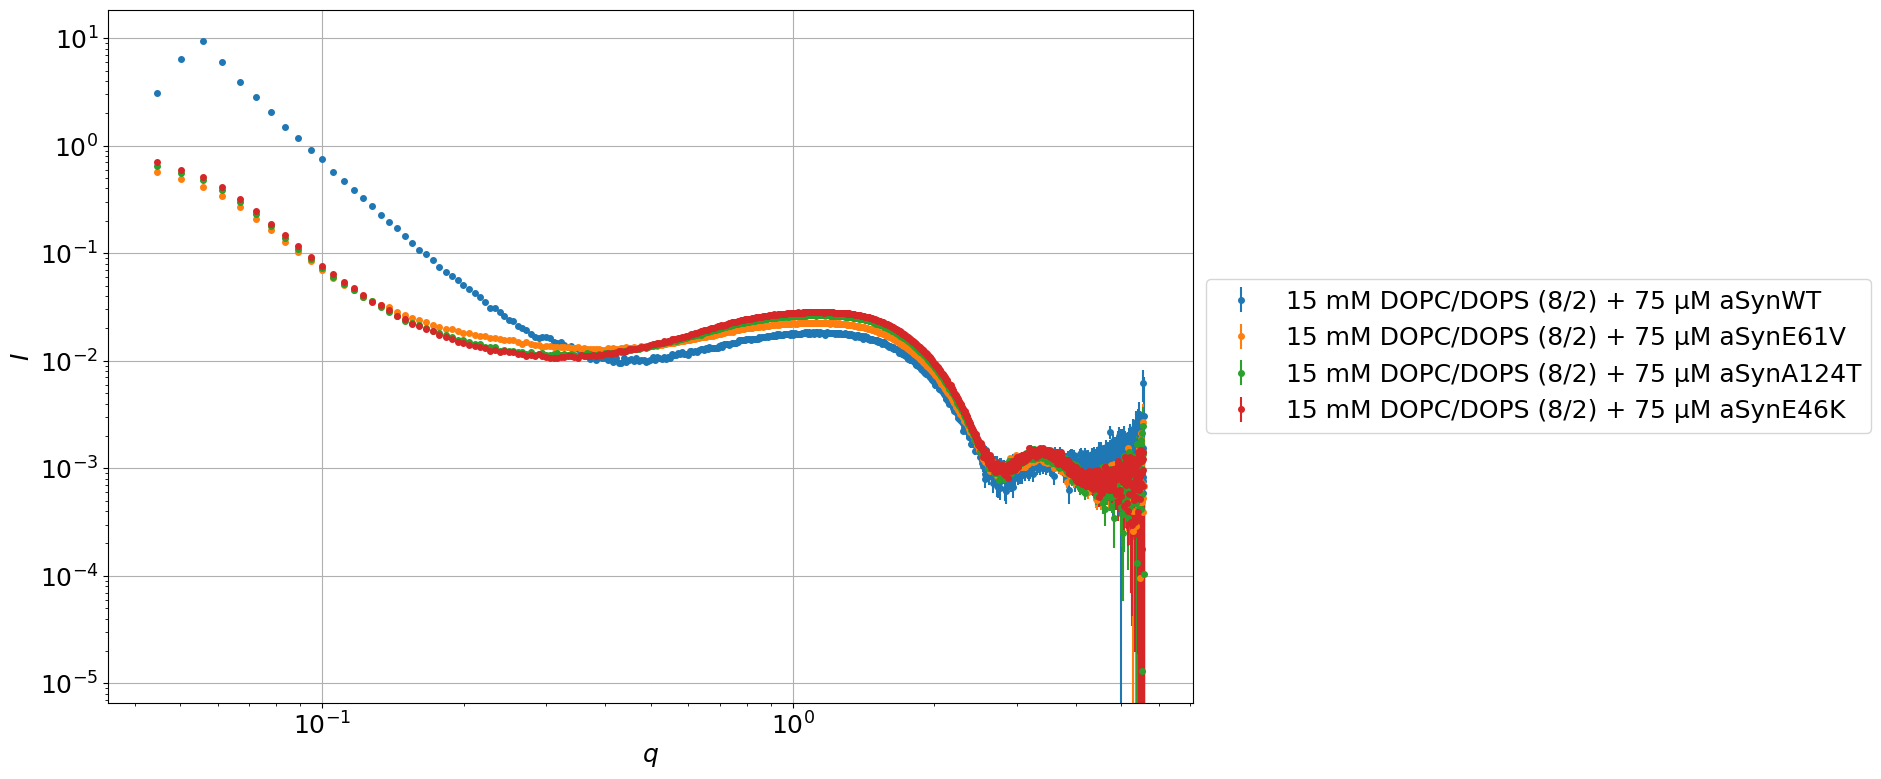

In [20]:
who = [
    "BVII_S4", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynWT",
    "BVII_S10", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynE61V",
    "BVII_S15", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynA124T",
    "BVII_S20", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynE46K",
]
BM29.plot_together(who, "", min_cutoff=0, max_cutoff=10)